# TP2 : enrichissement du corpus CAMille, Le Soir en 1960

Ce notebook rassemble mes analyses des 100 pages du Soir de 1960. J'y cherche les mots-clés de l'année, je construis un nuage de mots, je repère les personnes, lieux et organisations les plus cités, puis j'étudie le sentiment exprimé dans dix phrases.

In [1]:
import os
import re
from collections import Counter, defaultdict

import yake
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from IPython.display import Image
import spacy
import pandas as pd
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

c:\Users\DERRICK\tac\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Choix de l'année et des fichiers

In [2]:
year = 1960
txt_path = "../../data/txt/"
temp_path = "../../data/tmp"

files = sorted([f for f in os.listdir(txt_path) if f.endswith('.txt') and f"_{year}-" in f])
len(files)

100

## 1. Les mots-clés de l'année avec YAKE

YAKE repère les expressions importantes de chaque page. Je garde celles de deux mots, comme « Congo belge » ou « Nations Unies », puis je regarde lesquelles reviennent le plus souvent au fil de l'année.

In [3]:
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)

# Mots-clés de deux mots de chaque page de l'année
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        text = fh.read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1960-01-10_01-00018.txt mentions these keywords: Agence Rossel, l’Agence Rossel, Ecrire Agence, Faire offre, Rossel num, IMPORTANTE SOCIETE, Importante firme, BRUXELLES CHERCHE, Importante société, Firme Importante, curriculum vitae, offre manuscrite, vltae Agence...
KB_JB838_1960-01-12_01-00011.txt mentions these keywords: Van den, Van der, classements officiels, Coq Anglais, Van Houtte, Country Club, Léopold Club, Van Blesebroeck, Astrld Club, Van Belle, Baudouin Club...
KB_JB838_1960-01-13_01-00009.txt mentions these keywords: VAN LOOY, Van Stcenbergen, Rik Van, DIVISION III, Fort Jaco, Grand Prix, grand temps, Dimanche division, dimanche dernier...
KB_JB838_1960-01-21_01-00014.txt mentions these keywords: chemise lavée, CHEMISES LAVÉES, Office Propriétaires, Propriétaires Tél, WATERLOO TéL, maison rapport, belle maison, PRIX TARIF, francs Office, bonne maison...
KB_JB838_1960-01-22_01-00015.txt mentions these keywords: LOUER App, Pastilles Antibiotiques, FER FORGE, spac. a

In [4]:
# Les expressions qui reviennent dans le plus grand nombre de pages
year_keywords = Counter()
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        text = fh.read()
    for kw, score in kw_extractor.extract_keywords(text):
        if len(kw.split()) == 2:
            year_keywords[kw] += 1

year_keywords.most_common(30)

[('Agence Rossel', 17),
 ('Ecrire Agence', 11),
 ('Rossel num', 9),
 ('l’Agence Rossel', 6),
 ('Faire offre', 6),
 ('Congo belge', 5),
 ('New York', 5),
 ('demeurant rue', 5),
 ('Bruxelles Tél', 5),
 ('curriculum vitae', 4),
 ('Van den', 4),
 ('Rik Van', 4),
 ('Grand Prix', 4),
 ('JOURNAL QUOTIDIEN', 4),
 ('habitant rue', 4),
 ('Bruxelles dem', 4),
 ('Van Looy', 4),
 ('Nations Unies', 4),
 ('offre manuscrite', 3),
 ('DIVISION III', 3),
 ('Propriétaires Tél', 3),
 ('rue Van', 3),
 ('Opel Rek', 3),
 ('SOIR MERCREDI', 3),
 ('d’une fracture', 3),
 ('Dem. fem', 3),
 ('l’AGENCE ROSSEL', 3),
 ('domicilié rue', 3),
 ('lundi matin', 3),
 ('gouvernement belge', 3)]

## 2. Le nuage de mots de 1960

Je rassemble le texte des 100 pages, je retire les mots qui n'apportent rien, puis j'affiche les mots les plus fréquents. La liste des mots à retirer s'est construite en trois étapes, en regardant à chaque fois ce qui encombrait encore le nuage.

In [5]:
nltk.download('stopwords')

# Liste de départ : mots vides de NLTK et mots ajoutés dans le cours
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

# Itération 1 (1960) : vocabulaire et abréviations des petites annonces
sw += ["rue", "tél", "téléph", "app", "ecr", "écrire", "ecrire", "prés", "brux",
       "trav", "enf", "mod", "fem", "culs", "conf", "agence", "demande", "offre",
       "cherche", "présenter", "vente", "avenue", "mme", "bon", "bonne", "très",
       "prix", "vis", "soir"]

# Itération 2 (1960) : dates, durées et mots courants
sw += ["ans", "mois", "jours", "jour", "heures", "temps", "année", "matin", "midi",
       "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche",
       "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août",
       "septembre", "octobre", "novembre", "décembre", "avant", "peu", "toute",
       "quelques", "leurs", "vers", "devant", "déjà", "toujours", "etc", "chez",
       "celui", "alors", "fois", "également", "quatre", "plusieurs", "près", "lieu",
       "suite", "fin", "part", "partie", "place", "grand", "grande", "premier",
       "première", "dernier", "nouveau", "petit", "gros", "mal", "cours", "libre",
       "service"]

# Itération 3 (1960) : abréviations d'annonces encore présentes et mots vides restants
sw += ["réf", "mat", "rem", "gar", "bat", "bur", "bel", "mén", "pers", "louer",
       "dactylo", "bilingue", "firme", "dame", "importante", "ceux", "vue", "effet",
       "heure", "semaine", "demi", "neuf", "rien", "jamais", "ailleurs", "car",
       "point", "moment"]

sw = set(sw)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
# Rassembler le texte des 100 pages dans un fichier temporaire
content_list = []
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        content_list.append(fh.read())

if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as fh:
    fh.write(' '.join(content_list))

In [7]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    with open(output_path, "w", encoding='utf-8') as output:
        with open(input_path, 'r', encoding='utf-8') as f:
            text = f.read()
            words = nltk.wordpunct_tokenize(text)
            kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
            kept_string = " ".join(kept)
            output.write(kept_string)
    return f'Output has been written in {output_path}!'

clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1960_clean.txt!'

In [8]:
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as fh:
    after = fh.read()

frequencies = Counter(after.split())
print(frequencies.most_common(50))

[('BRUXELLES', 1112), ('MAISON', 357), ('BELGIQUE', 346), ('BELGE', 333), ('CONGO', 294), ('FRANCS', 288), ('PAYS', 277), ('ANVERS', 270), ('JEUNE', 264), ('JEAN', 258), ('TRAVAIL', 251), ('SAINT', 247), ('ÉQUIPE', 223), ('MINISTRE', 217), ('SITUATION', 216), ('FRANCE', 215), ('ÉTAT', 212), ('BELGES', 210), ('CENTRE', 208), ('PARIS', 207), ('GÉNÉRAL', 195), ('TOUR', 194), ('FRANÇAIS', 193), ('HOMME', 193), ('GOUVERNEMENT', 191), ('ENFANTS', 187), ('DIVISION', 186), ('PRÉSIDENT', 186), ('LOUISE', 175), ('FEMME', 175), ('LOI', 175), ('ORDRE', 173), ('VIE', 173), ('BUREAU', 173), ('SOCIÉTÉ', 170), ('VOITURE', 169), ('LIÈGE', 169), ('HOMMES', 165), ('MARCHÉ', 164), ('CONSEIL', 162), ('MONDE', 162), ('CHAUSSÉE', 159), ('MILLIONS', 156), ('NAMUR', 155), ('NOUVELLE', 155), ('RAPPORT', 152), ('DÉBUT', 151), ('COUR', 150), ('NORD', 149), ('PIERRE', 146)]


Ce nuage est le même que celui de s2_wordcloud.ipynb càd mêmes mots, mêmes tailles. Seule la position des mots change, car elle est tirée au hasard à chaque génération. L'image utilisée dans le rapport est wordcloud_1960.png.

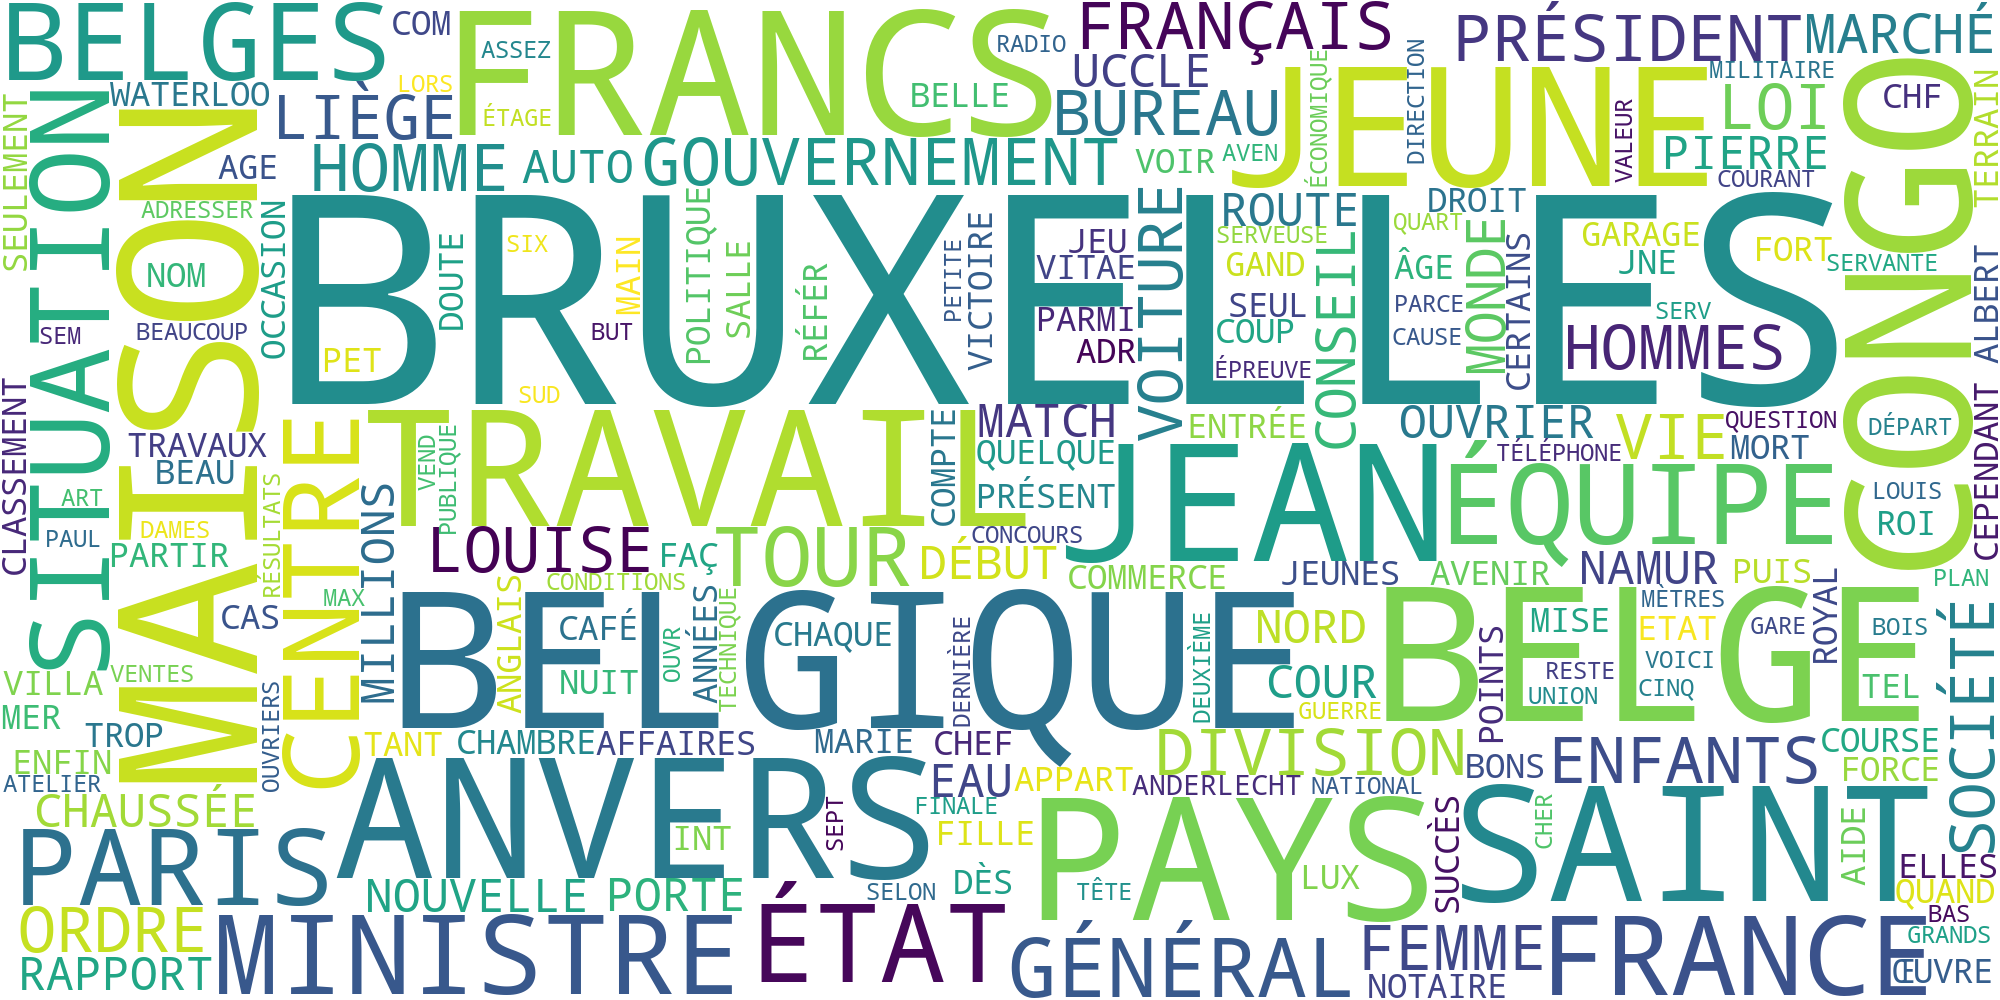

In [9]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## 3. Les personnes, organisations et lieux cités en 1960

Le modèle français de spaCy repère dans chaque page les noms de personnes, d'organisations et de lieux. Je compte ceux qui reviennent le plus souvent, en écartant le bruit des petites annonces, puis je regroupe les différentes façons d'écrire le nom de quelques grandes figures de l'année.

In [10]:
nlp = spacy.load('fr_core_news_md')

In [11]:
%%time
# Lire les textes de l'année
texts = []
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        texts.append(fh.read())

# Traiter les textes un par un et compter les personnes, organisations et lieux
people = defaultdict(int)
organisations = defaultdict(int)
places = defaultdict(int)

for doc in nlp.pipe(texts, disable=["morphologizer", "parser", "attribute_ruler", "lemmatizer"]):
    for ent in doc.ents:
        if len(ent.text) > 3:
            if ent.label_ == "PER":
                people[ent.text] += 1
            elif ent.label_ == "ORG":
                organisations[ent.text] += 1
            elif ent.label_ == "LOC":
                places[ent.text] += 1

CPU times: total: 1min 21s
Wall time: 1min 25s


In [12]:
# Entités à exclure : bruit des petites annonces et mots courants mal reconnus
excluded = {
    "rossel", "agence rossel", "agence rossel num", "rossel num", "ecrire ag", "ecag", "s'adr",
    "culs", "curr", "curric", "trav", "atel", "entret", "pr entret", "pr mén", "k dem",
    "exlg", "inst", "jard", "billng", "référ", "brux", "téléph", "- tél", "s.d.b", "i960",
    "bonne", "monsieur", "lundi", "etat", "centre", "firme", "téléphone", "import",
    "promotion", "parc", "employee", "mutuel", "credit", "assurances", "galeries",
    "manœuvres", "intimité", "service du personnel", "s. a.",
}

In [13]:
# Trier et imprimer les 30 entités les plus fréquentes de chaque type
for label, counts in [("Personnes", people), ("Organisations", organisations), ("Lieux", places)]:
    print(f"--- {label} ---")
    sorted_counts = [(e, n) for e, n in sorted(counts.items(), key=lambda kv: kv[1], reverse=True) if e.lower() not in excluded]
    for entity, freq in sorted_counts[:30]:
        print(f"{entity} apparait {freq} fois dans le corpus")

--- Personnes ---
Louise apparait 53 fois dans le corpus
Van Looy apparait 39 fois dans le corpus
Albert apparait 36 fois dans le corpus
Marie apparait 36 fois dans le corpus
Jean apparait 29 fois dans le corpus
O. N. U. apparait 24 fois dans le corpus
Reine apparait 22 fois dans le corpus
Robert apparait 22 fois dans le corpus
général de Gaulle apparait 21 fois dans le corpus
M. Khrouchtchev apparait 21 fois dans le corpus
Roger apparait 20 fois dans le corpus
Janssens apparait 19 fois dans le corpus
A. P. apparait 19 fois dans le corpus
Joseph apparait 17 fois dans le corpus
Molière apparait 17 fois dans le corpus
A.F.P. apparait 17 fois dans le corpus
Brugmann apparait 16 fois dans le corpus
Elisabethville apparait 16 fois dans le corpus
Dumont apparait 15 fois dans le corpus
Daems apparait 15 fois dans le corpus
Louis apparait 15 fois dans le corpus
A. F. P. apparait 15 fois dans le corpus
Mertens apparait 14 fois dans le corpus
Jacques apparait 14 fois dans le corpus
Desmet appara

### Les grandes figures de 1960, toutes formes du nom confondues

In [14]:
# Additionner toutes les entités PER qui contiennent le nom recherché
personnalites = ["Lumumba", "Kasa", "Tshombe", "Baudouin", "Eyskens", "Hammarskj",
                 "Khrouchtchev", "Gaulle", "Eisenhower", "Kennedy", "Van Looy"]
for nom in personnalites:
    total = sum(freq for entity, freq in people.items() if nom.lower() in entity.lower())
    print(f"{nom} : {total} mentions")

Lumumba : 26 mentions
Kasa : 9 mentions
Tshombe : 25 mentions
Baudouin : 16 mentions
Eyskens : 13 mentions
Hammarskj : 10 mentions
Khrouchtchev : 30 mentions
Gaulle : 34 mentions
Eisenhower : 18 mentions
Kennedy : 19 mentions
Van Looy : 53 mentions


## 4. Le sentiment exprimé dans dix phrases de 1960

Je cherche d'abord des phrases qui parlent des grands sujets de l'année ou qui expriment une émotion, puis j'en choisis dix. Je mesure leur polarité et leur subjectivité avec TextBlob, et je compare ces résultats avec un modèle Transformers.

In [16]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")

In [17]:
# Découper les textes en phrases et garder celles qui parlent des grands sujets de l'année ou qui expriment une émotion
keywords = ["Congo", "Katanga", "Lumumba", "Tshombe", "Kennedy", "Khrouchtchev", "Van Looy",
            "émue", "heureux", "magnifique", "superbe", "odieuse", "atroce", "malheureusement",
            "monstrueuse", "déplore", "délirante"]
candidates = []
for f in files:
    with open(os.path.join(txt_path, f), 'r', encoding='utf-8') as fh:
        text = fh.read().replace("\n", " ")
    for sentence in re.split(r'(?<=[.!?])\s+', text):
        if 70 < len(sentence) < 220 and any(k in sentence for k in keywords):
            candidates.append((f, sentence))
len(candidates)

324

In [18]:
# Afficher les 50 premières phrases candidates, avec le fichier d'origine
for f, sentence in candidates[:50]:
    print(f, "|", sentence)

KB_JB838_1960-01-12_01-00011.txt | L'Anversols, nous l'avons déjà précisé, s’embarquera pour le Congo belge .à la .ftn du mois, en vue de s'aligner, en compagnie de Réné Baeten et de Nie Jan- seri, du côté belge, S ten Luridin, Bill N11®1 Son,: Smith;.
KB_JB838_1960-01-12_01-00011.txt | L’homme qui doute do, Van;iLooy : .— ^ L, *5 - : : Il est 'difficile; de parler .cyclisme sans prononcer le nom de TtlkuVan Looy.
KB_JB838_1960-01-12_01-00011.txt | Je crois même que j te n'aurais pas engage Van Looy a aller au’Tour de France, si je l’avais eu à mon service, et ceci .pour des raisons autres que celles, qui lé lui font, dédaigner maintenant.
KB_JB838_1960-01-13_01-00009.txt | MERCREDI 13 JANVIER 1960 - - M A ^ -2éH A F“ CYCLISME RI K VAN LOOY disputera toutes les classiques du printemps Rik Van Looy est actuellement en Italie.
KB_JB838_1960-01-13_01-00009.txt | Une chose est certaine, cependant' : Rik Van Looy a renoncé uu Tour d’Espagne et au Grand Prix Cyclomotoriste.
KB_JB838_1960-01-

Les 324 phrases ont été lues (seules 50 sont affichées). J'en ai choisi 10, lisibles et porteuses d'un sentiment.

In [19]:
# Les 10 phrases retenues
phrases = [
    "Politiquement, la situation au Katanga paraît être la plus préoccupante.",
    "L'entrée en action des troupes belges a permis de rétablir rapidement la situation à Kabalo, Goma et Elisabethville où, malheureusement, on déplore la mort de cinq Européens, abattus par les rebel- les.",
    "EN PRÉSENCE D'UNE FOULE ÉMUE Le Roi accueille à Saventhem les « paras » rentrant du Congo Réception délirante à Bruxelles pour les hommes des 11' et 14' compagnies Saventhem, mercredi matin.",
    "Il est heureux que le ministre Gilson et Cometro aient envisagé depuis longtemps les urgences d’intervenir militairement au Congo.",
    "Ivanov, dans un article destiné à prouver le rôle de « metteur en scène et d'acteur principal » que « les Etats-Unis assument dans toute l’aventure impérialiste, odieuse et sanglante qui se déroule au Congo ».",
    "Dans l’immédiat, il est impossible de recruter pour le Congo des médecins à l’étranger, les conditions de travail au Congo étant inconnues, et la situation pouvant encore s'aggraver dans quelques semaines.",
    "Venant tout de suite après sa vibrante démonstration de la veille à Forli, cette victoire de Van Looy a confirmé l’excellente condition qu’il détient actuellement.",
    "Le concert se termina par une magnifique exécution des Danses de Galanta de Zoltan Kodaly.",
    "La méchanceté des comparses est si monstrueuse et dépourvue de nuance qu'on ne croit guère à leurs turpitudes de mélodrame.",
    "Ils étaient 130 hommes, femmes et enfants qui, il y a deux jôurs, avaient été vaccinés contre la rage: quatorze sont déjà-morts dans d’atroces souffrances.",
]
len(phrases)

10

In [20]:
# Fichier d'origine de chaque phrase retenue
for phrase in phrases:
    sources = [f for f, sentence in candidates if sentence == phrase]
    print(sources, "|", phrase[:60])

['KB_JB838_1960-07-10_01-00001.txt'] | Politiquement, la situation au Katanga paraît être la plus p
['KB_JB838_1960-07-10_01-00001.txt'] | L'entrée en action des troupes belges a permis de rétablir r
['KB_JB838_1960-08-04_01-00001.txt'] | EN PRÉSENCE D'UNE FOULE ÉMUE Le Roi accueille à Saventhem le
['KB_JB838_1960-08-05_01-00007.txt'] | Il est heureux que le ministre Gilson et Cometro aient envis
['KB_JB838_1960-08-05_01-00007.txt'] | Ivanov, dans un article destiné à prouver le rôle de « mette
['KB_JB838_1960-08-05_01-00007.txt'] | Dans l’immédiat, il est impossible de recruter pour le Congo
['KB_JB838_1960-05-27_01-00007.txt'] | Venant tout de suite après sa vibrante démonstration de la v
['KB_JB838_1960-09-27_01-00009.txt'] | Le concert se termina par une magnifique exécution des Danse
['KB_JB838_1960-10-28_01-00002.txt'] | La méchanceté des comparses est si monstrueuse et dépourvue 
['KB_JB838_1960-12-02_01-00004.txt'] | Ils étaient 130 hommes, femmes et enfants qui, il y a deux j


In [21]:
# Analyse de chaque phrase avec la fonction du cours
for phrase in phrases:
    print(phrase)
    get_sentiment(phrase)
    print()

Politiquement, la situation au Katanga paraît être la plus préoccupante.
This text is 15% positive and 10% subjective.

L'entrée en action des troupes belges a permis de rétablir rapidement la situation à Kabalo, Goma et Elisabethville où, malheureusement, on déplore la mort de cinq Européens, abattus par les rebel- les.
This text is 14% negative and 5% subjective.

EN PRÉSENCE D'UNE FOULE ÉMUE Le Roi accueille à Saventhem les « paras » rentrant du Congo Réception délirante à Bruxelles pour les hommes des 11' et 14' compagnies Saventhem, mercredi matin.
This text is 10% positive and 35% subjective.

Il est heureux que le ministre Gilson et Cometro aient envisagé depuis longtemps les urgences d’intervenir militairement au Congo.
This text is 70% positive and 80% subjective.

Ivanov, dans un article destiné à prouver le rôle de « metteur en scène et d'acteur principal » que « les Etats-Unis assument dans toute l’aventure impérialiste, odieuse et sanglante qui se déroule au Congo ».
This 

In [22]:
# Résumer les résultats dans un tableau
pd.set_option('display.max_colwidth', None)
results = []
for phrase in phrases:
    polarity, subjectivity = tb(phrase).sentiment
    results.append({"Phrase": phrase, "Polarité": round(polarity, 2), "Subjectivité": round(subjectivity, 2)})
table = pd.DataFrame(results)
table

,Phrase,Polarité,Subjectivité
0,"Politiquement, la situation au Katanga paraît être la plus préoccupante.",0.15,0.10
1,"L'entrée en action des troupes belges a permis de rétablir rapidement la situation à Kabalo, Goma et Elisabethville où, malheureusement, on déplore la mort de cinq Européens, abattus par les rebel- les.",-0.14,0.05
2,"EN PRÉSENCE D'UNE FOULE ÉMUE Le Roi accueille à Saventhem les « paras » rentrant du Congo Réception délirante à Bruxelles pour les hommes des 11' et 14' compagnies Saventhem, mercredi matin.",0.10,0.35
3,Il est heureux que le ministre Gilson et Cometro aient envisagé depuis longtemps les urgences d’intervenir militairement au Congo.,0.70,0.80
4,"Ivanov, dans un article destiné à prouver le rôle de « metteur en scène et d'acteur principal » que « les Etats-Unis assument dans toute l’aventure impérialiste, odieuse et sanglante qui se déroule au Congo ».",-0.20,0.30
5,"Dans l’immédiat, il est impossible de recruter pour le Congo des médecins à l’étranger, les conditions de travail au Congo étant inconnues, et la situation pouvant encore s'aggraver dans quelques semaines.",-0.09,0.27
6,"Venant tout de suite après sa vibrante démonstration de la veille à Forli, cette victoire de Van Looy a confirmé l’excellente condition qu’il détient actuellement.",0.36,0.50
7,Le concert se termina par une magnifique exécution des Danses de Galanta de Zoltan Kodaly.,1.00,1.00
8,La méchanceté des comparses est si monstrueuse et dépourvue de nuance qu'on ne croit guère à leurs turpitudes de mélodrame.,-0.80,1.00
9,"Ils étaient 130 hommes, femmes et enfants qui, il y a deux jôurs, avaient été vaccinés contre la rage: quatorze sont déjà-morts dans d’atroces souffrances.",-0.90,0.80


### Comparaison avec le modèle Transformers

In [23]:
tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")

sentiment_analyser = pipeline('sentiment-analysis', model=model, tokenizer=tokenizer)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10334.85it/s]


In [24]:
# Ajouter au tableau l'avis du modèle Transformers (étiquette et confiance)
predictions = [sentiment_analyser(phrase)[0] for phrase in phrases]
table["Transformers"] = [p["label"] for p in predictions]
table["Confiance"] = [round(p["score"], 2) for p in predictions]
table

,Phrase,Polarité,Subjectivité,Transformers,Confiance
0,"Politiquement, la situation au Katanga paraît être la plus préoccupante.",0.15,0.10,NEGATIVE,0.70
1,"L'entrée en action des troupes belges a permis de rétablir rapidement la situation à Kabalo, Goma et Elisabethville où, malheureusement, on déplore la mort de cinq Européens, abattus par les rebel- les.",-0.14,0.05,NEGATIVE,0.61
2,"EN PRÉSENCE D'UNE FOULE ÉMUE Le Roi accueille à Saventhem les « paras » rentrant du Congo Réception délirante à Bruxelles pour les hommes des 11' et 14' compagnies Saventhem, mercredi matin.",0.10,0.35,NEGATIVE,0.82
3,Il est heureux que le ministre Gilson et Cometro aient envisagé depuis longtemps les urgences d’intervenir militairement au Congo.,0.70,0.80,POSITIVE,0.53
4,"Ivanov, dans un article destiné à prouver le rôle de « metteur en scène et d'acteur principal » que « les Etats-Unis assument dans toute l’aventure impérialiste, odieuse et sanglante qui se déroule au Congo ».",-0.20,0.30,POSITIVE,0.57
5,"Dans l’immédiat, il est impossible de recruter pour le Congo des médecins à l’étranger, les conditions de travail au Congo étant inconnues, et la situation pouvant encore s'aggraver dans quelques semaines.",-0.09,0.27,NEGATIVE,0.71
6,"Venant tout de suite après sa vibrante démonstration de la veille à Forli, cette victoire de Van Looy a confirmé l’excellente condition qu’il détient actuellement.",0.36,0.50,POSITIVE,0.80
7,Le concert se termina par une magnifique exécution des Danses de Galanta de Zoltan Kodaly.,1.00,1.00,POSITIVE,0.92
8,La méchanceté des comparses est si monstrueuse et dépourvue de nuance qu'on ne croit guère à leurs turpitudes de mélodrame.,-0.80,1.00,NEGATIVE,0.96
9,"Ils étaient 130 hommes, femmes et enfants qui, il y a deux jôurs, avaient été vaccinés contre la rage: quatorze sont déjà-morts dans d’atroces souffrances.",-0.90,0.80,POSITIVE,0.53
